# E-commerce Customer Behavior Analysis

Exploratory analysis of 500 responses in the supplied `consumer_shopping_behavior_survey.csv`. The notebook summarizes demographics and shopping preferences, then examines satisfaction, review trust, purchase regret, and buy-now-pay-later (BNPL) use.

**Scope and limitations.** Dataset source, sampling method, survey wording, and representativeness were not provided. Findings are descriptive of these survey responses; observational comparisons do not establish causation.

## 1. Load and inspect the data

Run the notebook from the project directory. The CSV is read in place and is not modified.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal, pearsonr, spearmanr

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
DATA_RELATIVE_PATH = Path("data/raw/consumer_shopping_behavior_survey.csv")
search_paths = [Path.cwd() / DATA_RELATIVE_PATH, Path.cwd().parent / DATA_RELATIVE_PATH]
DATA_PATH = next((candidate.resolve() for candidate in search_paths if candidate.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"CSV not found at project-root or notebooks-relative path: {DATA_RELATIVE_PATH}")
df = pd.read_csv(DATA_PATH)
TOTAL_RESPONDENTS = len(df)
print(f"Loaded {TOTAL_RESPONDENTS} rows and {df.shape[1]} columns from {DATA_PATH.resolve()}")

Loaded 500 rows and 30 columns from C:\python Project for Data Analysis\EDA Project\data\raw\consumer_shopping_behavior_survey.csv


In [2]:
df.head()

,Response_ID,Timestamp,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,...,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore,Best_Shopping_Mode
0,1,01/08/2026 12:30:25,20,Male,NaN,Philippines,"Under $1,000",Equal mix,Often,Physical stores,...,Never,Under $50,Digital wallet,"Yes, occasionally",6.0,7.0,2.0,More variety,No delivery wait,Online
1,2,21/06/2026 13:52:02,24,Male,Employed part-time,Brazil,"Under $1,000",In-store only,Often,Local e-commerce,...,Often,Under $50,Digital wallet,"No, never",5.0,8.0,3.0,NaN,Try product before buying,Offline
2,3,15/08/2026 04:24:18,22,Female,Student,India,"Under $1,000",Equal mix,Always,Local e-commerce,...,Sometimes,$150-300,Credit Card,"No, never",7.0,6.0,2.0,Better prices,Trust,Online
3,4,23/06/2026 21:24:21,20,Male,Student,NaN,"Under $1,000",In-store only,Occasionally,Brand websites,...,Never,Under $50,Debit Card,"No, never",8.0,7.0,3.0,Better prices,Try product before buying,Equal / both
4,5,20/08/2026 16:24:47,41,Male,Employed full-time,United States,"$1,000-3,000",Equal mix,Occasionally,NaN,...,Sometimes,$50-150,Debit Card,"No, never",6.0,8.0,2.0,Convenience,Trust,Equal / both


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 30 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Response_ID                         500 non-null    int64  
 1   Timestamp                           500 non-null    str    
 2   Age                                 478 non-null    str    
 3   Gender                              484 non-null    str    
 4   Occupation_Status                   479 non-null    str    
 5   Country_Region                      480 non-null    str    
 6   Monthly_Income_Range                479 non-null    str    
 7   Shop_Most_Where                     484 non-null    str    
 8   Online_Shopping_Frequency           481 non-null    str    
 9   Preferred_Platform                  486 non-null    str    
 10  Primary_Device                      492 non-null    str    
 11  Top_Spending_Category               476 non-null    str 

In [4]:
missing = pd.DataFrame({"missing_count": df.isna().sum(),
                        "missing_percent": (100 * df.isna().mean()).round(1)})
missing.sort_values("missing_count", ascending=False)

,missing_count,missing_percent
Reason_Prefer_Online,54,10.8
Regret_After_Purchase_Frequency,52,10.4
Best_Shopping_Mode,51,10.2
Trust_In_Online_Reviews_Score,50,10.0
Reason_Prefer_InStore,45,9.0
Online_Shopping_Satisfaction_Score,43,8.6
Price_Comparison_Frequency,26,5.2
Likely_To_Buy_After_Ad_Score,25,5.0
Top_Spending_Category,24,4.8
Makes_Shopping_List,24,4.8


In [5]:
print(f"Exact duplicate rows: {df.duplicated().sum()}")
print(f"Unique response IDs: {df['Response_ID'].nunique()} of {TOTAL_RESPONDENTS}")
print(f"Duplicate response IDs: {df['Response_ID'].duplicated().sum()}")

Exact duplicate rows: 0
Unique response IDs: 500 of 500
Duplicate response IDs: 0


## 2. Clean fields and document missing data

Age is converted to numeric; blank ages and nonnumeric entries become missing. Timestamps use the source day/month/year format. Missing values in six selected categorical fields are labeled `Unknown`; other missing values are left as-is and excluded only where a calculation needs them.

In [6]:
age_raw = df["Age"].copy()
df["Age"] = pd.to_numeric(age_raw, errors="coerce")
invalid_age = age_raw.notna() & df["Age"].isna()
df["Timestamp"] = pd.to_datetime(df["Timestamp"],
                                  format="%d/%m/%Y %H:%M:%S", errors="coerce")
print(f"Blank ages: {age_raw.isna().sum()}; nonblank unparseable ages: {invalid_age.sum()}")
if invalid_age.any(): print("Unparsed age entries:", sorted(age_raw[invalid_age].astype(str).unique()))
print(f"Unparsed timestamps: {df['Timestamp'].isna().sum()}")
print(f"Timestamp range: {df['Timestamp'].min()} to {df['Timestamp'].max()}")

Blank ages: 22; nonblank unparseable ages: 8
Unparsed age entries: ['...', 'Gunay B', 'N/A123', 'Priya K', 'asdf', 'rahul', 'test', 'xyz']
Unparsed timestamps: 0
Timestamp range: 2026-06-20 02:10:10 to 2026-08-24 20:59:32


In [7]:
unknown_cols = ["Gender", "Occupation_Status", "Country_Region", "Shop_Most_Where",
                "Preferred_Platform", "Preferred_Payment_Method"]
missing_before_fill = df[unknown_cols].isna().sum().rename("missing labeled Unknown")
df[unknown_cols] = df[unknown_cols].fillna("Unknown")
missing_before_fill.to_frame()

,missing labeled Unknown
Gender,16
Occupation_Status,21
Country_Region,20
Shop_Most_Where,16
Preferred_Platform,14
Preferred_Payment_Method,15


### Incomplete final-section responses

Thirty rows (6.0%) have no answer in any of the six final survey fields below. These rows are retained; earlier answers remain available for analyses that use them. The file alone cannot establish whether the pattern reflects survey attrition.

In [8]:
final_section = ["Online_Shopping_Satisfaction_Score", "Trust_In_Online_Reviews_Score",
                 "Regret_After_Purchase_Frequency", "Reason_Prefer_Online",
                 "Reason_Prefer_InStore", "Best_Shopping_Mode"]
final_missing = df[final_section].isna().all(axis=1)
print(f"Rows missing all six final-section fields: {final_missing.sum()} / {TOTAL_RESPONDENTS} ({final_missing.mean():.1%})")
df.loc[final_missing, "Timestamp"].dt.date.value_counts().sort_index().rename("incomplete rows by date")

Rows missing all six final-section fields: 30 / 500 (6.0%)


Timestamp
2026-06-20    1
2026-06-22    1
2026-06-24    1
2026-06-29    1
2026-06-30    1
2026-07-02    1
2026-07-03    1
2026-07-05    1
2026-07-06    1
2026-07-07    2
2026-07-09    1
2026-07-10    1
2026-07-16    1
2026-07-24    2
2026-07-27    2
2026-07-28    1
2026-07-30    1
2026-08-02    1
2026-08-03    1
2026-08-15    2
2026-08-16    1
2026-08-17    1
2026-08-18    1
2026-08-19    1
2026-08-21    1
2026-08-24    1
Name: incomplete rows by date, dtype: int64

## 3. Demographics and shopping preferences

Age 18 is classified in `18-25`. Age summaries exclude records without a usable age; each score mean uses its own valid observations. Tables show total group size separately from valid outcome counts.

In [9]:
age_bins = [-np.inf, 17, 25, 35, 50, np.inf]
age_labels = ["Under 18", "18-25", "26-35", "36-50", "Over 50"]
df["Age_Group"] = pd.cut(df["Age"], bins=age_bins, labels=age_labels, right=True)
age_summary = df.groupby("Age_Group", observed=True).agg(
    total_respondents=("Response_ID", "count"),
    valid_satisfaction=("Online_Shopping_Satisfaction_Score", "count"),
    avg_satisfaction=("Online_Shopping_Satisfaction_Score", "mean"),
    valid_trust=("Trust_In_Online_Reviews_Score", "count"),
    avg_trust=("Trust_In_Online_Reviews_Score", "mean"),
    valid_regret=("Regret_After_Purchase_Frequency", "count"),
    avg_regret=("Regret_After_Purchase_Frequency", "mean"),
).round(2)
age_summary

,total_respondents,valid_satisfaction,avg_satisfaction,valid_trust,avg_trust,valid_regret,avg_regret
Age_Group,,,,,,,
Under 18,33,30,7.60,30,6.83,30,2.10
18-25,273,251,7.03,242,6.00,247,2.25
26-35,110,103,7.17,102,6.14,100,2.17
36-50,54,45,7.02,48,6.48,45,1.93


In [10]:
age18 = df["Age"].eq(18)
print(f"Age 18 respondents classified as 18-25: {(df.loc[age18, 'Age_Group'] == '18-25').sum()} of {age18.sum()}")
print(f"Valid ages: {df['Age'].notna().sum()} / {TOTAL_RESPONDENTS}; mean age: {df['Age'].mean():.2f}; median: {df['Age'].median():.0f}")

Age 18 respondents classified as 18-25: 45 of 45
Valid ages: 470 / 500; mean age: 25.02; median: 22


In [11]:
df["Age"].describe().round(2)

count    470.00
mean      25.02
std        7.52
min       16.00
25%       20.00
50%       22.00
75%       30.00
max       50.00
Name: Age, dtype: float64

In [12]:
df["Reason_Prefer_Online"].value_counts(dropna=False).rename("responses")

Reason_Prefer_Online
More variety      170
Convenience       157
Better prices      81
NaN                54
Not applicable     38
Name: responses, dtype: int64

`Not applicable` is a recorded response; missing answers are shown separately.

In [13]:
in_store_reasons = pd.crosstab(df["Shop_Most_Where"], df["Reason_Prefer_InStore"], dropna=False)
in_store_reasons.rename_axis(index="shops most where", columns="reason prefer in-store")

reason prefer in-store,No delivery wait,Not applicable,Trust,Try product before buying,NaN
shops most where,,,,,
Equal mix,54,42,49,74,29
In-store only,15,10,16,21,9
Online only,43,20,51,46,5
Unknown,7,0,3,4,2


Country table: top eight recorded country values. Satisfaction means use valid satisfaction responses; regular-BNPL rates exclude missing BNPL answers. Total and valid counts are separate.

In [14]:
top_countries = df["Country_Region"].value_counts().head(8).index
country = df[df["Country_Region"].isin(top_countries)].groupby("Country_Region").agg(
    total_respondents=("Response_ID", "count"),
    valid_satisfaction=("Online_Shopping_Satisfaction_Score", "count"),
    avg_satisfaction=("Online_Shopping_Satisfaction_Score", "mean"),
    valid_bnpl=("Uses_BNPL_Installments", "count"),
    regular_bnpl=("Uses_BNPL_Installments", lambda s: s.eq("Yes, regularly").sum()),
)
country["regular_bnpl_rate_pct"] = 100 * country["regular_bnpl"] / country["valid_bnpl"].replace(0, np.nan)
country.round(2)

,total_respondents,valid_satisfaction,avg_satisfaction,valid_bnpl,regular_bnpl,regular_bnpl_rate_pct
Country_Region,,,,,,
Brazil,38,35,7.11,34,7,20.59
Egypt,25,23,6.52,24,1,4.17
India,66,59,6.78,66,12,18.18
Indonesia,26,23,7.43,26,4,15.38
Kenya,26,25,7.24,25,7,28.00
Mexico,35,32,7.25,32,3,9.38
Philippines,23,22,7.09,22,2,9.09
United States,56,49,7.39,55,3,5.45


Occupation averages use valid observations for each measure. BNPL rate denominators exclude missing answers; the output includes both total and valid counts.

In [15]:
occupation = df.groupby("Occupation_Status").agg(
    total_respondents=("Response_ID", "count"),
    valid_impulse=("Impulse_Purchase_Frequency", "count"),
    avg_impulse=("Impulse_Purchase_Frequency", "mean"),
    valid_discount=("Discount_Importance_Score", "count"),
    avg_discount_importance=("Discount_Importance_Score", "mean"),
    valid_bnpl=("Uses_BNPL_Installments", "count"),
    regular_bnpl=("Uses_BNPL_Installments", lambda s: s.eq("Yes, regularly").sum()),
)
occupation["regular_bnpl_rate_pct"] = 100 * occupation["regular_bnpl"] / occupation["valid_bnpl"].replace(0, np.nan)
occupation.sort_values("avg_impulse", ascending=False).round(2)

,total_respondents,valid_impulse,avg_impulse,valid_discount,avg_discount_importance,valid_bnpl,regular_bnpl,regular_bnpl_rate_pct
Occupation_Status,,,,,,,,
Employed part-time,71,70,2.86,70,3.94,70,7,10.00
Student,238,233,2.61,227,3.80,230,31,13.48
Unknown,21,18,2.50,21,3.67,20,1,5.00
Employed full-time,118,112,2.46,108,3.90,117,16,13.68
Self-employed,33,33,2.45,32,3.78,33,4,12.12
Unemployed,19,18,2.44,19,3.47,18,1,5.56


## 4. Payment and spending category shares

Payment percentages use row totals after missing payment and shopping-mode answers were labeled `Unknown`. Spending-category shares use valid spending-category responses only; the denominator is shown per gender.

In [16]:
payment_counts = pd.crosstab(df["Shop_Most_Where"], df["Preferred_Payment_Method"])
payment_denominator = payment_counts.sum(axis=1).rename("row denominator")
payment_percent = payment_counts.div(payment_denominator, axis=0)
payment_counts

Preferred_Payment_Method,Cash,Credit Card,Debit Card,Digital wallet,Unknown
Shop_Most_Where,,,,,
Equal mix,34,52,68,88,6
In-store only,10,18,16,24,3
Online only,18,37,40,65,5
Unknown,2,2,5,6,1


In [17]:
payment_denominator.to_frame().join(payment_percent.mul(100).round(1).add_suffix(" share (%)"))

,row denominator,Cash share (%),Credit Card share (%),Debit Card share (%),Digital wallet share (%),Unknown share (%)
Shop_Most_Where,,,,,,
Equal mix,248,13.7,21.0,27.4,35.5,2.4
In-store only,71,14.1,25.4,22.5,33.8,4.2
Online only,165,10.9,22.4,24.2,39.4,3.0
Unknown,16,12.5,12.5,31.2,37.5,6.2


In [18]:
spend_counts = pd.crosstab(df["Gender"], df["Top_Spending_Category"])
spend_denominator = spend_counts.sum(axis=1).rename("valid category responses")
spend_percent = spend_counts.div(spend_denominator, axis=0)
spend_denominator.to_frame().join(spend_percent.mul(100).round(1).add_suffix(" share (%)"))

,valid category responses,Beauty & personal care share (%),Books share (%),Clothing share (%),Electronics share (%),Groceries share (%),miscellaneous share (%)
Gender,,,,,,,
Female,170,6.5,8.8,37.6,13.5,21.2,12.4
Male,242,8.3,6.6,40.5,16.1,18.2,10.3
Prefer not to say,49,10.2,10.2,22.4,24.5,18.4,14.3
Unknown,15,0.0,13.3,40.0,13.3,20.0,13.3


## 5. Review trust and satisfaction

Correlations use pairwise-complete observations. Pearson describes linear association; Spearman describes rank association. These tests are observational. Nonsignificance is not proof that an association is exactly zero.

In [19]:
trust_satisfaction = df[["Trust_In_Online_Reviews_Score", "Online_Shopping_Satisfaction_Score"]].dropna()
trust_satisfaction.describe().round(2)

,Trust_In_Online_Reviews_Score,Online_Shopping_Satisfaction_Score
count,437.00,437.00
mean,6.15,7.13
std,1.91,1.60
min,1.00,2.00
25%,5.00,6.00
50%,6.00,7.00
75%,7.00,8.00
max,10.00,10.00


In [20]:
trust_satisfaction = df[["Trust_In_Online_Reviews_Score", "Online_Shopping_Satisfaction_Score"]].dropna()
x = trust_satisfaction["Trust_In_Online_Reviews_Score"]
y = trust_satisfaction["Online_Shopping_Satisfaction_Score"]
pearson = pearsonr(x, y)
spearman = spearmanr(x, y)
pd.DataFrame({"method": ["Pearson", "Spearman"],
              "correlation": [pearson.statistic, spearman.statistic],
              "p_value": [pearson.pvalue, spearman.pvalue],
              "valid_pairs": [len(x), len(x)]}).round(4)

,method,correlation,p_value,valid_pairs
0,Pearson,-0.0179,0.7092,437
1,Spearman,-0.0216,0.6524,437


In these responses both correlations are near zero and nonsignificant at 0.05. This is insufficient evidence of an association in this sample, not proof of no population association.

## 6. BNPL and purchase regret

The Kruskal–Wallis test compares regret-score distributions across BNPL groups using pairwise-complete observations. This is a descriptive, observational comparison.

In [21]:
df["Uses_BNPL_Installments"].value_counts(dropna=False).rename("responses")

Uses_BNPL_Installments
No, never            290
Yes, occasionally    138
Yes, regularly        60
NaN                   12
Name: responses, dtype: int64

In [22]:
df["Regret_After_Purchase_Frequency"].describe().round(2)

count    448.00
mean       2.19
std        0.90
min        1.00
25%        1.00
50%        2.00
75%        3.00
max        4.00
Name: Regret_After_Purchase_Frequency, dtype: float64

In [23]:
df["Regret_After_Purchase_Frequency"].value_counts(dropna=False).sort_index().rename("responses")

Regret_After_Purchase_Frequency
1.0    115
2.0    167
3.0    133
4.0     33
NaN     52
Name: responses, dtype: int64

In [24]:
bnpl_regret = df[["Uses_BNPL_Installments", "Regret_After_Purchase_Frequency"]].dropna()
bnpl_summary = bnpl_regret.groupby("Uses_BNPL_Installments").agg(
    respondents_in_analysis=("Regret_After_Purchase_Frequency", "size"),
    avg_regret=("Regret_After_Purchase_Frequency", "mean"),
    median_regret=("Regret_After_Purchase_Frequency", "median"),
    std_regret=("Regret_After_Purchase_Frequency", "std"),
).round(2)
bnpl_summary

,respondents_in_analysis,avg_regret,median_regret,std_regret
Uses_BNPL_Installments,,,,
"No, never",254,2.22,2.0,0.90
"Yes, occasionally",127,2.20,2.0,0.93
"Yes, regularly",56,2.05,2.0,0.86


In [25]:
bnpl_order = ["No, never", "Yes, occasionally", "Yes, regularly"]
groups = [bnpl_regret.loc[bnpl_regret["Uses_BNPL_Installments"].eq(g),
                           "Regret_After_Purchase_Frequency"] for g in bnpl_order]
kw = kruskal(*groups)
print(f"Kruskal-Wallis H={kw.statistic:.3f}, p={kw.pvalue:.4f}; pairwise-complete n={len(bnpl_regret)}")

Kruskal-Wallis H=1.826, p=0.4013; pairwise-complete n=437


The test is nonsignificant at 0.05. The group summaries are descriptive and do not show that BNPL use causes more or less regret.

## 7. Visualizations

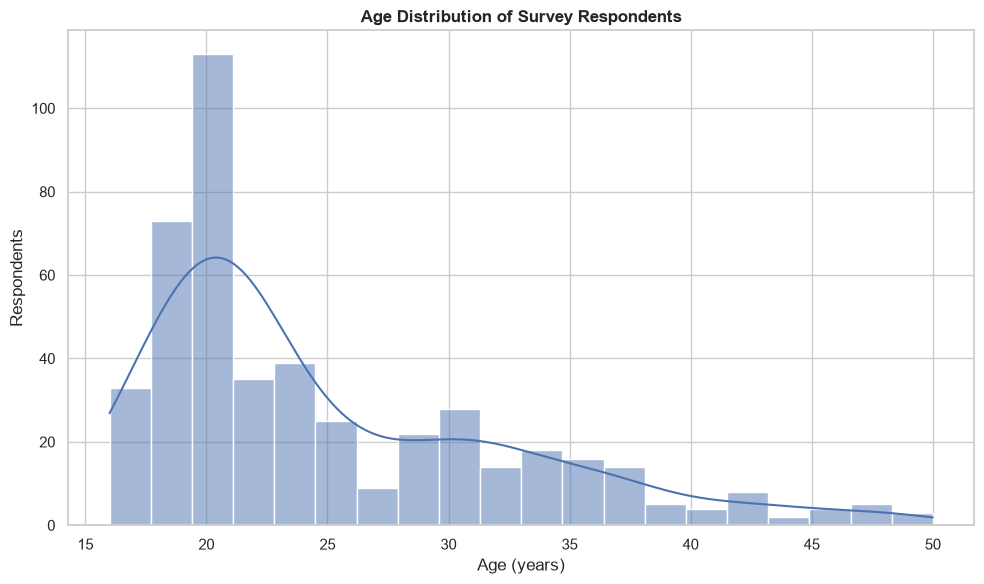

In [26]:
sns.histplot(df["Age"].dropna(), bins=20, kde=True, color="#4C72B0")
plt.title("Age Distribution of Survey Respondents", fontweight="bold")
plt.xlabel("Age (years)"); plt.ylabel("Respondents")
plt.tight_layout(); plt.show()

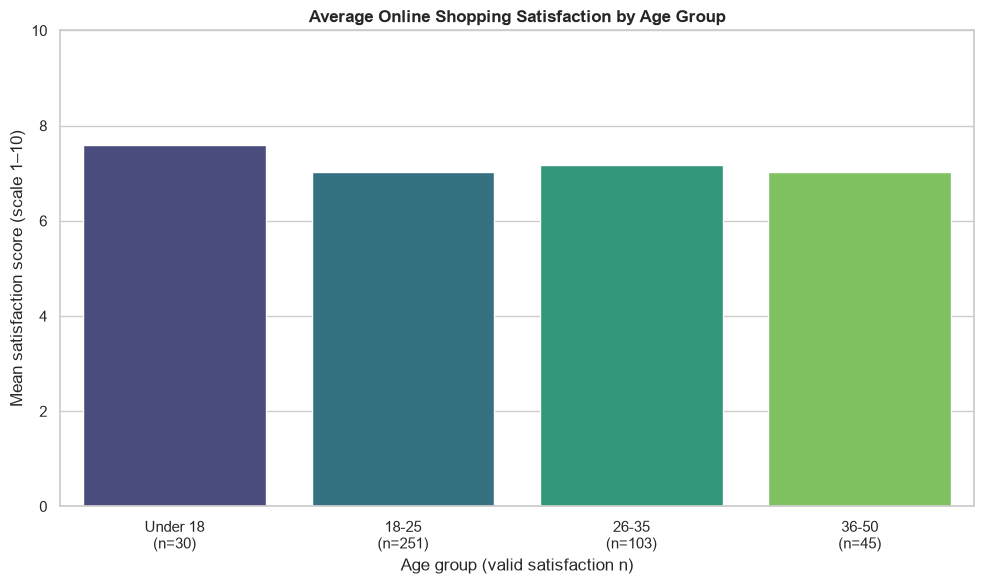

In [27]:
age_plot = age_summary.loc[age_summary["valid_satisfaction"].gt(0)].copy()
age_plot["label"] = [f"{g}\n(n={n})" for g, n in zip(age_plot.index.astype(str), age_plot["valid_satisfaction"])]
sns.barplot(data=age_plot, x="label", y="avg_satisfaction", hue="label", palette="viridis", legend=False)
plt.title("Average Online Shopping Satisfaction by Age Group", fontweight="bold")
plt.xlabel("Age group (valid satisfaction n)"); plt.ylabel("Mean satisfaction score (scale 1–10)")
plt.ylim(0, 10); plt.tight_layout(); plt.show()

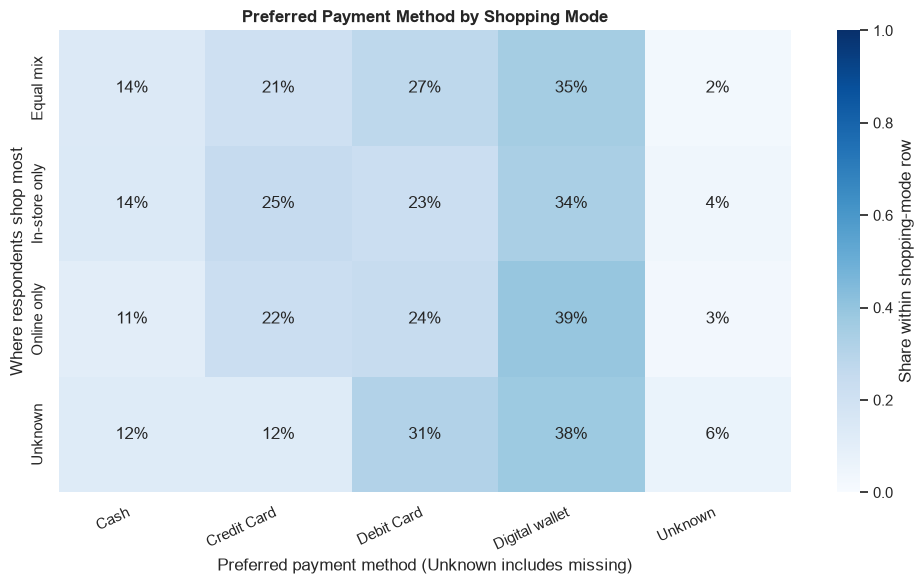

In [28]:
sns.heatmap(payment_percent, annot=True, cmap="Blues", fmt=".0%", vmin=0, vmax=1,
            cbar_kws={"label": "Share within shopping-mode row"})
plt.title("Preferred Payment Method by Shopping Mode", fontweight="bold")
plt.xlabel("Preferred payment method (Unknown includes missing)"); plt.ylabel("Where respondents shop most")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

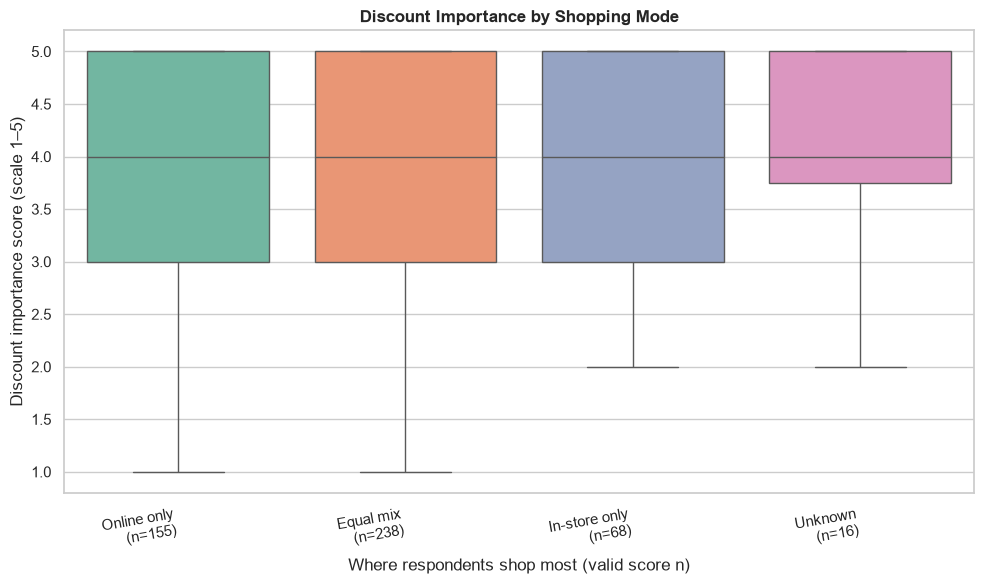

In [29]:
shop_order = ["Online only", "Equal mix", "In-store only", "Unknown"]
discount_n = df.groupby("Shop_Most_Where")["Discount_Importance_Score"].count()
discount_labels = [f"{g}\n(n={int(discount_n.get(g, 0))})" for g in shop_order]
sns.boxplot(data=df, x="Shop_Most_Where", y="Discount_Importance_Score", order=shop_order,
            hue="Shop_Most_Where", hue_order=shop_order, palette="Set2", legend=False)
plt.title("Discount Importance by Shopping Mode", fontweight="bold")
plt.xlabel("Where respondents shop most (valid score n)"); plt.ylabel("Discount importance score (scale 1–5)")
plt.xticks(range(len(shop_order)), discount_labels, rotation=10, ha="right"); plt.tight_layout(); plt.show()

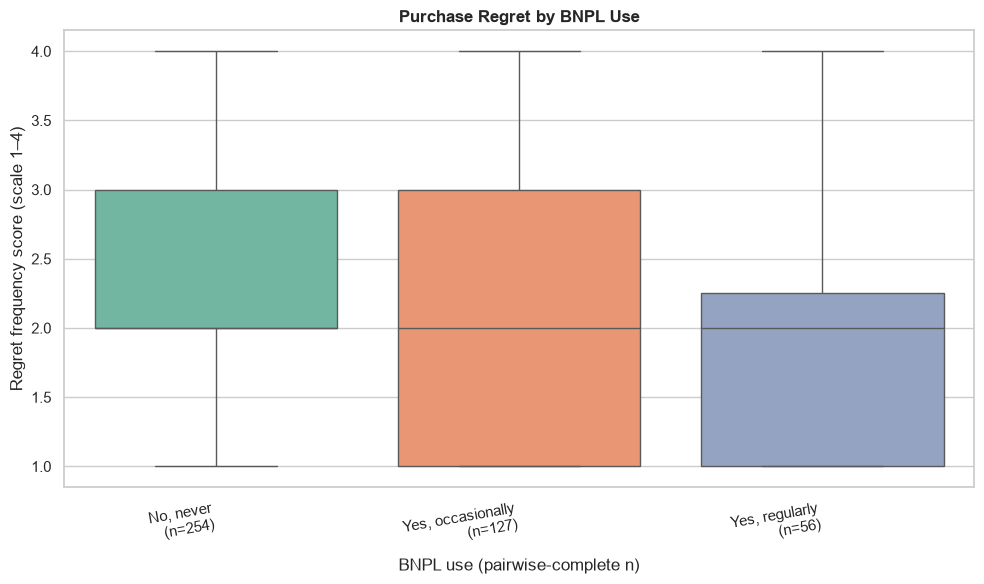

In [30]:
sns.boxplot(data=bnpl_regret, x="Uses_BNPL_Installments", y="Regret_After_Purchase_Frequency",
            order=bnpl_order, hue="Uses_BNPL_Installments", hue_order=bnpl_order,
            palette="Set2", legend=False)
plt.title("Purchase Regret by BNPL Use", fontweight="bold")
bnpl_n = bnpl_regret.groupby("Uses_BNPL_Installments").size()
bnpl_labels = [f"{g}\n(n={int(bnpl_n.get(g, 0))})" for g in bnpl_order]
plt.xlabel("BNPL use (pairwise-complete n)"); plt.ylabel("Regret frequency score (scale 1–4)")
plt.xticks(range(len(bnpl_order)), bnpl_labels, rotation=10, ha="right"); plt.tight_layout(); plt.show()

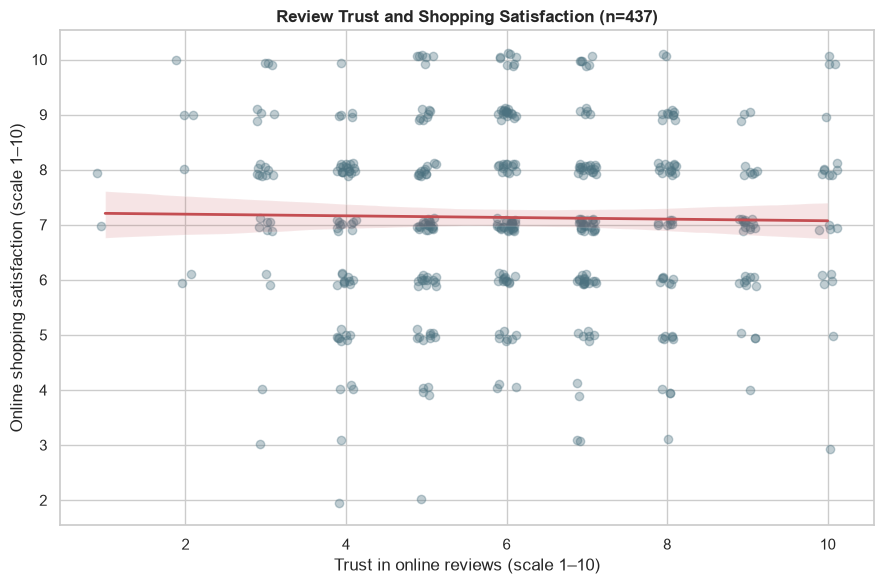

In [31]:
plt.figure(figsize=(9, 6))
sns.regplot(data=trust_satisfaction, x="Trust_In_Online_Reviews_Score",
            y="Online_Shopping_Satisfaction_Score", x_jitter=0.12, y_jitter=0.12,
            scatter_kws={"alpha": 0.35, "color": "#4C7280"},
            line_kws={"color": "#C44E52", "linewidth": 2})
plt.title(f"Review Trust and Shopping Satisfaction (n={len(trust_satisfaction)})", fontweight="bold")
plt.xlabel("Trust in online reviews (scale 1–10)"); plt.ylabel("Online shopping satisfaction (scale 1–10)")
plt.tight_layout(); plt.show()

## 8. Summary

- Summaries use available responses; total respondents and valid observation counts are distinguished.
- Review-trust correlations are close to zero and nonsignificant in this sample. This does not prove there is no broader association.
- The BNPL–regret comparison is nonsignificant and observational; it does not support a causal conclusion.
- Dataset source, sampling details, and survey wording were not supplied, so population-level findings and business recommendations are outside this analysis.